# Bender

T-Rex up to guide 4, the thermal and the cold path.

- **Diagnostics**: write the .instr file of the section to `mcstas_input/trex_extraction/` of the
  repository and run the diagnostics of McStasScript into `mcstas_output/`.
- **Bender efficiency**: scan the rotation of the bender and see how it passes each band of
  wavelengths. The beam is measured at the exit of guide 4b, with one monitor bin per band. A run
  without the bender, through the thermal guide 4a, gives the intensity to compare with. The
  figure has one curve per band, divided by that intensity.

`simulate` runs McStas into two folders of `mcstas_output/`, replacing the earlier ones. `plot`
only reads them. The cell that calls `simulate()` is commented out, so by default the notebook
replots the last scan. Nothing here is saved for the documentation: `scripts/docs_trex_bender.py`
makes its figures.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mcstasscript as ms
import numpy as np

from mcdgs.diagnostics.trex.bender import BenderScan, read_angles, read_spectra, transmission
from mcdgs.diagnostics.trex.extraction import Extraction
from mcdgs.instruments.trex.guides.bispectral import BENDER_ROTATION
from mcdgs.mcstas.builder import build_mcstas, default_input_dir
from mcdgs.mcstas.run_folders import default_output_dir, run_folder
from mcdgs.mcstas.simulation import Simulation

# the repository: the first folder up from here that holds pyproject.toml
WORK_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
SCAN_FILE = default_output_dir(WORK_DIR) / "bender_scan" / "mccode.h5"
BENDER_OUT_FILE = default_output_dir(WORK_DIR) / "bender_out" / "mccode.h5"

## The instruments

`Extraction`, from `mcdgs.diagnostics.trex.extraction`, is the section up to guide 4.
`BenderScan`, from `mcdgs.diagnostics.trex.bender`, adds a wavelength monitor at the exit of
guide 4b.

## Diagnostics

Create the extraction section, print its summary and write its .instr file.

In [3]:
extraction = Extraction()
print(extraction)

trex_extraction = build_mcstas(extraction, input_path=default_input_dir(extraction, WORK_DIR))
trex_extraction.write_full_instrument()
print(f"\nWritten to {trex_extraction.input_path}")

Extraction 'trex_extraction'

Params:
param      value      unit    comment
---------  ---------  ------  ------------------------------------
bender_in  False              True = bender in, False = bender out
b_rot      -0.397881  deg     rotation of the cold neutron bender

Instrument parameters (McStas):
name       value      unit    comment
---------  ---------  ------  -----------------------------------
bender_in  0                  bender in = 1, out = 0
b_rot      -0.397881  deg     rotation of the cold neutron bender

Components, in the order of the beam (m, deg):
name         component      at                         rotated            relative     position
-----------  -------------  -------------------------  -----------------  -----------  -------------------------
origin       Progress_bar   [0, 0, 0]                  [0, 0, 0]          -            [0, 0, 0]
source       ESS_butterfly  [0, 0, 0]                  [0, 0, 0]          -            [0, 0, 0]
arm_nboa     Arm 

In [4]:
trex_extraction.show_components()
trex_extraction.set_parameters(bender_in=1)
trex_extraction.show_parameters()
# trex_extraction.show_diagram(variable="l", limits=[0, 6])
# trex_extraction.show_instrument(backend="matplotlib_2d", projection="zx")

origin  Progress_bar 
  AT      (0, 0, 0) ABSOLUTE 
  ROTATED (0, 0, 0) ABSOLUTE
source  ESS_butterfly 
  AT      (0, 0, 0) ABSOLUTE 
  ROTATED (0, 0, 0) ABSOLUTE
arm_nboa  Arm 
  AT      (-0.002022816656807591, 0, 1.895927) ABSOLUTE 
  ROTATED (0, -0.21499811064881996, 0) ABSOLUTE
guide_1  Guide_gravity 
  AT      (0, 0, 0) RELATIVE arm_nboa 
  ROTATED (0, 0, 0) RELATIVE arm_nboa
guide_2  Guide_gravity 
  AT      (0, 0, 1.0004070432038372) RELATIVE arm_nboa 
  ROTATED (0, 0, 0) RELATIVE arm_nboa
guide_3  Guide_gravity 
  AT      (0, 0, 2.0008140864076744) RELATIVE arm_nboa 
  ROTATED (0, 0, 0) RELATIVE arm_nboa
arm_guide_4  Arm 
  AT      (-0.015081221289166724, 0, 5.40065) ABSOLUTE 
  ROTATED (0, -0.2133503302705942, 0) ABSOLUTE
guide_4a  Guide_gravity 
  AT      (0, 0, 0) RELATIVE arm_guide_4 
  ROTATED (0, 0, 0) RELATIVE arm_guide_4
bender  Pol_bender 
  AT      (0, 0, 0) RELATIVE arm_guide_4 
  ROTATED (0, b_rot, 0) RELATIVE arm_guide_4
guide_4b  Guide_gravity 
  AT      (0, 0, 0.

The beam after the source, after guide 3 and at the exit of guide 4b, for the path set by
`bender_in` above.

In [5]:
diag = ms.Diagnostics(trex_extraction)

output_path = run_folder(default_output_dir(WORK_DIR), None, "diagnose")
diag.settings(ncount=1e6, suppress_output=True, mpi="auto", output_path=str(output_path))
diag.show_settings()

diag.clear_points()
for component in ("source", "guide_3", "guide_4b"):
    # rays="all": a limited list stops early, which leaves the intensities too low
    diag.add_point(after=component, rays="all")  # pyright: ignore[reportArgumentType]

diag.run()

Instrument settings:
  ncount:           1.00e+06
  mpi:              auto 
  output_path:      /Users/bingli/Documents/GitHub/mcdgs/mcstas_output/20261103-213633_diagnose
  run_path:         /Users/bingli/Documents/GitHub/mcdgs/mcstas_input/trex_extraction
  package_path:     /Users/bingli/Documents/GitHub/mcdgs/.pixi/envs/default/share/mcstas/resources
  executable_path:  /Users/bingli/Documents/GitHub/mcdgs/.pixi/envs/default/bin
  executable:       mcrun
  force_compile:    True
  NeXus:            False
  save_comp_pars:   False


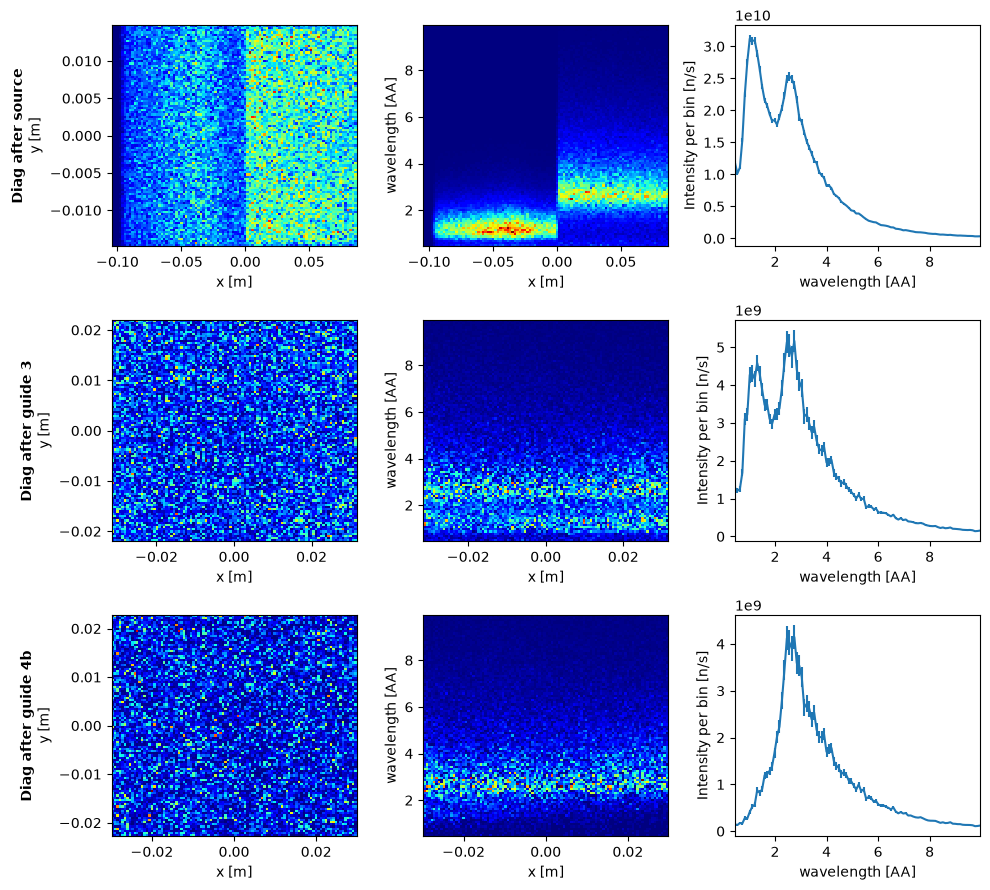

In [6]:
diag.clear_views()
diag.add_view("x", "y", bins=100)
# diag.add_view("vx", "vy", bins=200)
# diag.add_view("dx", "dy", bins=100)
# diag.add_view("l", bins=100)
# diag.add_view("t", bins=100)
diag.add_view("x", "l", bins=100)
# diag.add_view("t", "l", bins=100)
diag.add_view("l")
diag.plot()
plt.show()  # McStasScript only draws the figure

## Bender efficiency

In [7]:
def simulate() -> None:
    """Scan the rotation of the bender and run once without it."""
    angles = np.linspace(-0.8, 0.1, 19)  # deg, values of b_rot
    ncount = 1e7  # neutrons per angle
    seed = 1

    simulation = Simulation(BenderScan(), work_dir=WORK_DIR)
    folder_name = SCAN_FILE.parent.name
    simulation.scan("b_rot", angles, folder_name, ncount=ncount, seed=seed, bender_in=1)
    print(f"Wrote {SCAN_FILE}")
    folder_name = BENDER_OUT_FILE.parent.name
    simulation.run(folder_name, ncount=ncount, seed=seed, bender_in=0)
    print(f"Wrote {BENDER_OUT_FILE}")

To run a new scan, uncomment the next cell. It replaces the earlier scan.

In [8]:
# simulate()

In [9]:
def plot() -> None:
    """Plot the intensity against the rotation of the bender, one curve per wavelength band.

    Each curve is divided by the intensity of its band without the bender, which is therefore 1.
    Everything comes from the files that :func:`simulate` writes.
    """
    angles = read_angles(SCAN_FILE)
    centers, intensity, error = read_spectra(SCAN_FILE)
    _, bender_out, bender_out_error = read_spectra(BENDER_OUT_FILE)
    reference, reference_error = bender_out[0], bender_out_error[0]

    ratio, ratio_error = transmission(intensity, error, reference, reference_error)
    half_width = (centers[1] - centers[0]) / 2

    _, ax = plt.subplots()
    for band, center in enumerate(centers):
        label = f"{center:.4g}±{half_width:.4g} Å"
        ax.errorbar(angles, ratio[:, band], ratio_error[:, band], color=f"C{band}", label=label)
    ax.axhline(1, color="black", linestyle="--", label="bender out")
    ax.axvline(
        BENDER_ROTATION,
        color="black",
        linestyle=":",
        label=f"b_rot = {BENDER_ROTATION:.3f} deg",
    )
    ax.set_ylim(bottom=0)
    ax.set_xlabel("b_rot [deg]")
    ax.set_ylabel("Intensity after guide 4b / bender out")
    ax.legend()
    # ax.spines[["top", "right"]].set_visible(False)
    # fig.legend(loc="outside right upper", frameon=False)

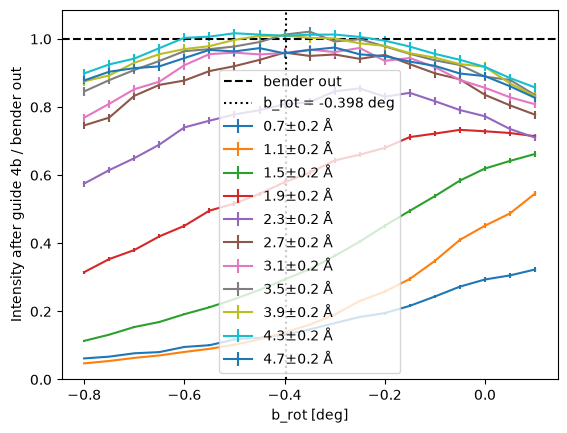

In [10]:
plot()
plt.show()